In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving traffic_dataset.csv to traffic_dataset.csv


In [ ]:
df = pd.read_csv("traffic_dataset.csv")
!ls

sample_data  traffic_dataset.csv


In [ ]:
df.head()

/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,reading_id,road_id,sensor_id,timestamp,vehicle_count,avg_speed,density,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12
0,1.0,R001,S001,20-08-2026 00:00,50.0,46.26,0.33,NaN,NaN,NaN,NaN,NaN,NaN
1,2.0,R002,S002,20-08-2026 00:00,45.0,43.33,0.30,NaN,NaN,NaN,NaN,NaN,NaN
2,3.0,R003,S003,20-08-2026 00:00,27.0,51.87,0.18,NaN,NaN,NaN,NaN,NaN,NaN
3,4.0,R004,S004,20-08-2026 00:00,16.0,58.63,0.11,NaN,NaN,NaN,NaN,NaN,NaN
4,5.0,R005,S005,20-08-2026 00:00,49.0,48.24,0.33,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.shape

(841, 13)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 841 entries, 0 to 840
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   reading_id     840 non-null    float64
 1   road_id        841 non-null    object 
 2   sensor_id      840 non-null    object 
 3   timestamp      840 non-null    object 
 4   vehicle_count  839 non-null    float64
 5   avg_speed      839 non-null    float64
 6   density        839 non-null    float64
 7   Unnamed: 7     1 non-null      object 
 8   Unnamed: 8     1 non-null      object 
 9   Unnamed: 9     1 non-null      object 
 10  Unnamed: 10    1 non-null      float64
 11  Unnamed: 11    1 non-null      float64
 12  Unnamed: 12    1 non-null      float64
dtypes: float64(7), object(6)
memory usage: 85.5+ KB


In [ ]:
df.describe()

,reading_id,vehicle_count,avg_speed,density,Unnamed: 10,Unnamed: 11,Unnamed: 12
count,840.000000,839.00000,839.000000,839.000000,1.0,1.00,1.00
mean,419.966667,65.38975,42.595006,0.436427,48.0,46.41,0.32
std,242.944225,38.29931,10.557788,0.255065,NaN,NaN,NaN
min,1.000000,10.00000,17.620000,0.070000,48.0,46.41,0.32
25%,209.750000,33.00000,34.995000,0.220000,48.0,46.41,0.32
50%,419.500000,57.00000,44.510000,0.380000,48.0,46.41,0.32
75%,630.250000,91.00000,51.235000,0.610000,48.0,46.41,0.32
max,840.000000,150.00000,60.840000,1.000000,48.0,46.41,0.32


In [ ]:
df.isnull().sum()

,0
reading_id,1
road_id,0
sensor_id,1
timestamp,1
vehicle_count,2
avg_speed,2
density,2
Unnamed: 7,840
Unnamed: 8,840
Unnamed: 9,840


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["timestamp"] = pd.to_datetime(df["timestamp"], format="mixed", errors="coerce")

In [ ]:
df["timestamp"].isna().sum()

np.int64(2)

In [ ]:
df["hour"] = df["timestamp"].dt.hour

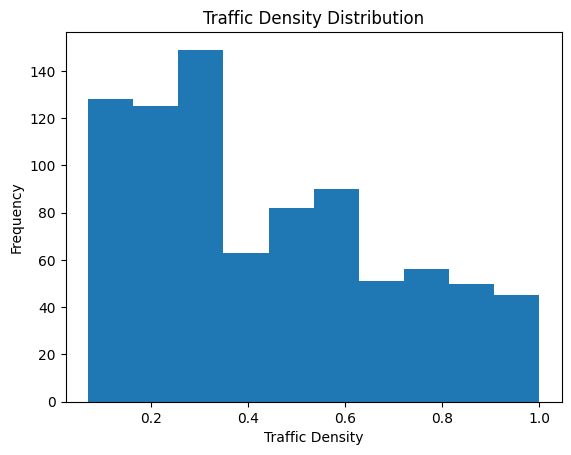

In [ ]:
plt.hist(df["density"])
plt.xlabel("Traffic Density")
plt.ylabel("Frequency")
plt.title("Traffic Density Distribution")
plt.show()

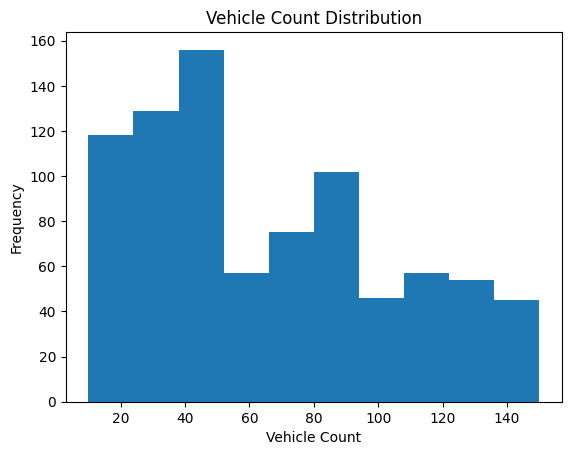

In [ ]:
plt.hist(df["vehicle_count"])
plt.xlabel("Vehicle Count")
plt.ylabel("Frequency")
plt.title("Vehicle Count Distribution")
plt.show()

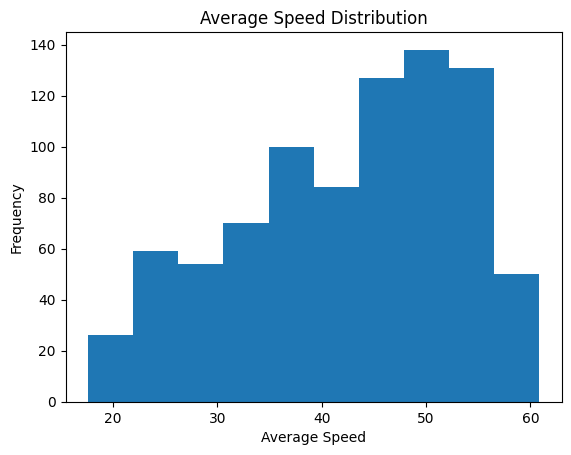

In [ ]:
plt.hist(df["avg_speed"])
plt.xlabel("Average Speed")
plt.ylabel("Frequency")
plt.title("Average Speed Distribution")
plt.show()

In [ ]:
df.groupby("road_id")["density"].mean().sort_values(ascending=False)

,density
road_id,
R005,0.444107
R002,0.437246
R001,0.435905
R003,0.433631
R004,0.431250
0.25,NaN
43,NaN


In [ ]:
df.groupby("hour")["density"].mean()

,density
hour,
0.0,0.200857
1.0,0.199714
2.0,0.202857
3.0,0.218286
4.0,0.203294
5.0,0.182857
6.0,0.191429
7.0,0.719143
8.0,0.715143


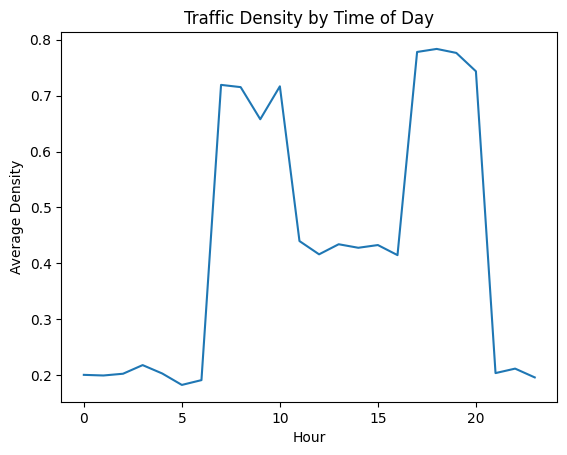

In [ ]:
df.groupby("hour")["density"].mean().plot()
plt.xlabel("Hour")
plt.ylabel("Average Density")
plt.title("Traffic Density by Time of Day")
plt.show()